In [1]:
import numpy as np
import pandas as pd

In [2]:
from scipy.io import loadmat

long_mat = loadmat("corr-offsite-results_1-12_winter_hour_train60_multi1_th50.mat")
print(long_mat.keys())   
short_mat = loadmat("short_term_cov.mat")
print(short_mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'allError', 'allError_NWP', 'allError_res', 'allNWPinfo', 'allVariance', 'allY_Fore', 'allY_Fore_res', 'allY_NWP', 'allY_Test', 'allY_int', 'maes', 'maes_nwp', 'maes_res'])
dict_keys(['__header__', '__version__', '__globals__', 'allVariance_Fore', 'allY_Fore', 'maes'])


In [3]:
short_mat["allVariance_Fore"].shape

(216, 216, 183)

In [4]:
import numpy as np

loc_idx = [7, 8] ## index for E05/E06
L_total = 9      ##total location for base model
ORDER = 'loc_first'   # flatten order

mu_long = np.asarray(long_mat["allY_Fore"])[:, loc_idx, :] ## pick data for E05/E06
mu_long = np.transpose(mu_long, (2, 1, 0))     ## 183*2*24

mu_short = np.asarray(short_mat["allY_Fore"])[:, loc_idx, :]
mu_short = np.transpose(mu_short, (2, 1, 0))        

y_raw = np.asarray(long_mat["allY_Test"]) ## 24*2*183
y_true = np.transpose(y_raw[:, :, :], (2, 1, 0)) 

D = mu_long.shape[0]  ## 183
L = 2

## flatten the data
if ORDER == 'hour_first':
    idx0 = np.array([h * L_total + loc_idx[0] for h in range(24)], dtype=int)
    idx1 = np.array([h * L_total + loc_idx[1] for h in range(24)], dtype=int)
elif ORDER == 'loc_first':
    idx0 = np.array([loc_idx[0] * 24 + h for h in range(24)], dtype=int)  ## 7*24+1-8*24 index for E05
    idx1 = np.array([loc_idx[1] * 24 + h for h in range(24)], dtype=int) ## index for E06
else:
    raise ValueError("ORDER must be 'hour_first' or 'loc_first'.")

# covariance for long term model
Sig_long_raw = np.asarray(long_mat["allVariance"])   # 216*216*183
if Sig_long_raw.ndim == 3 and Sig_long_raw.shape[0] == 24 * L_total:
    # (216,216,183) get covariance matrix by location
    Sig_long = np.empty((D, L, 24, 24))
    for d in range(D):
        S = Sig_long_raw[:, :, d] 
        Sig_long[d, 0] = S[np.ix_(idx0, idx0)]
        Sig_long[d, 1] = S[np.ix_(idx1, idx1)]
elif Sig_long_raw.ndim == 4 and Sig_long_raw.shape[:2] == (24, 24):
    # if raw covariance matrix in other form
    Ssel = Sig_long_raw[:, :, loc_idx, :]
    Sig_long = np.transpose(Ssel, (3, 2, 0, 1))
else:
    raise ValueError(f"Unexpected long covariance shape: {Sig_long_raw.shape}")

# covaraince for the short-term
Sig_short_raw = np.asarray(short_mat["allVariance_Fore"])  
if Sig_short_raw.ndim == 3 and Sig_short_raw.shape[0] == 24 * L_total:
    Sig_short = np.empty((D, L, 24, 24))
    for d in range(D):
        S = Sig_short_raw[:, :, d]
        Sig_short[d, 0] = S[np.ix_(idx0, idx0)]
        Sig_short[d, 1] = S[np.ix_(idx1, idx1)]
elif Sig_short_raw.ndim == 4 and Sig_short_raw.shape[:2] == (24, 24):
    if Sig_short_raw.shape[2] >= max(loc_idx)+1:
        Ssel = Sig_short_raw[:, :, loc_idx, :]
        Sig_short = np.transpose(Ssel, (3, 2, 0, 1))
    else:
        Sig_short = np.transpose(Sig_short_raw, (2, 0, 1))[:, None, :, :].repeat(2, axis=1)
elif Sig_short_raw.ndim == 2 and Sig_short_raw.shape == (24, 24):
    Sig_short = np.tile(Sig_short_raw, (D, 2, 1, 1))
else:
    raise ValueError(f"Unexpected short covariance shape: {Sig_short_raw.shape}")

# final mu and covaraince for the base model
muX, SigXX = mu_short, Sig_short     # (183,2,24), (183,2,24,24)
muY, SigYY = mu_long,  Sig_long      # (183,2,24), (183,2,24,24)

print("muX:", muX.shape, "SigXX:", SigXX.shape)
print("muY:", muY.shape, "SigYY:", SigYY.shape)
print("y_true:", y_true.shape)
# 预期输出：
# muX:   (183, 2, 24)  SigXX: (183, 2, 24, 24)
# muY:   (183, 2, 24)  SigYY: (183, 2, 24, 24)
# y_true:(183, 2, 24)


muX: (183, 2, 24) SigXX: (183, 2, 24, 24)
muY: (183, 2, 24) SigYY: (183, 2, 24, 24)
y_true: (183, 2, 24)


In [ ]:
import numpy as np
from scipy.optimize import minimize

# muX, muY, y_true: (D, 2, 24)
# SigXX, SigYY:     (D, 2, 24, 24)
D, L, H = muX.shape
assert (L, H) == (2, 24)

Wwin    = 45          # calibration window
S       = 1000        # Monte carlo
M_pairs = 10000       # pairs
seed    = 42          
I24     = np.eye(24)
eff     = D - Wwin    # test days

muZ_out      = np.empty((24, 2, eff))
SigZ_per_loc = np.empty((2, 24, 24, eff))
error_out    = np.empty((24, 2, eff))
alpha_seq    = np.empty(eff); ell_seq = np.empty(eff); rho_seq = np.empty(eff)
MAE_daily    = np.empty(eff); ES_daily = np.empty(eff)

t = np.arange(24, dtype=float)
TT_i = t[:, None]; TT_j = t[None, :]
rng_global = np.random.default_rng(seed)

def softplus(x):  
    return np.log1p(np.exp(x))

alpha_lo, alpha_hi = 0.05, 0.12 ## bound for alpha, change based on prior or unconstrained
bounds = [(alpha_lo, alpha_hi), (None, None), (None, None)]  # [alpha, l, r]

# warm start
theta_prev = np.array([0.10, 2.0, 0.0], dtype=float)  # [alpha0, l0, r0]

for d in range(Wwin, D):
    k   = d - Wwin
    win = np.arange(d - Wwin, d)
    Wlen= len(win)

    eps_bank = rng_global.standard_normal((Wlen, S, 48))  # 48=2*24
    i_pair   = rng_global.integers(0, S, size=M_pairs)
    j_pair   = rng_global.integers(0, S, size=M_pairs)
    m_pairs  = (i_pair != j_pair)
    i_pair, j_pair = i_pair[m_pairs], j_pair[m_pairs]

    # Cholesky decomposition
    SX_list = [[None]*2 for _ in range(Wlen)]
    SY_list = [[None]*2 for _ in range(Wlen)]
    for kk, dd in enumerate(win):
        for loc in range(2):
            # SigXX chol
            A = SigXX[dd, loc]
            jitter = 1e-6
            for _try in range(8):
                try:
                    SX_list[kk][loc] = np.linalg.cholesky(A + jitter * I24)
                    break
                except np.linalg.LinAlgError:
                    jitter *= 10.0
            # SigYY chol
            B = SigYY[dd, loc]
            jitter = 1e-6
            for _try in range(8):
                try:
                    SY_list[kk][loc] = np.linalg.cholesky(B + jitter * I24)
                    break
                except np.linalg.LinAlgError:
                    jitter *= 10.0

    # objective of ES
    def es_objective(theta):
        # theta = [alpha, l, r]
        alpha, l, r = theta
        ell = softplus(l)     # >0
        rho = np.tanh(r)      # (-1,1)
        ## weight
        w = np.exp(-alpha * (np.arange(24) + 1.0))
        Wmat = np.diag(w); IminusW = np.diag(1.0 - w)

        # RBF K(ell) normalize
        dist2 = (TT_i - TT_j)**2
        K = np.exp(-0.5 * dist2 / (ell**2 + 1e-12))
        evals = np.linalg.eigvalsh((K + K.T)/2.0)
        Kt = K / max(evals.max(), 1e-12)
        C = rho * Kt  # 24x24

        total = 0.0
        for kk, dd in enumerate(win):
            muZ_loc, SigZ_loc = [], []

            for loc in range(2):
                # mu
                muZ = Wmat @ muX[dd, loc] + IminusW @ muY[dd, loc]
                # cross-covariance
                SigXY = SX_list[kk][loc] @ C @ SY_list[kk][loc].T
                # final covariance
                SigZ = (Wmat @ SigXX[dd, loc] @ Wmat
                        + IminusW @ SigYY[dd, loc] @ IminusW
                        + Wmat @ SigXY @ IminusW
                        + IminusW @ SigXY.T @ Wmat)

                muZ_loc.append(muZ)
                SigZ_loc.append(SigZ)

            
            jitter = 1e-6
            for _ in range(8):
                try:
                    L0 = np.linalg.cholesky(SigZ_loc[0] + jitter * I24); break
                except np.linalg.LinAlgError: jitter *= 10.0
            jitter = 1e-6
            for _ in range(8):
                try:
                    L1 = np.linalg.cholesky(SigZ_loc[1] + jitter * I24); break
                except np.linalg.LinAlgError: jitter *= 10.0

            Lbd = np.zeros((48,48))
            Lbd[0:24,0:24] = L0
            Lbd[24:48,24:48] = L1

            mu_flat = np.concatenate([muZ_loc[0], muZ_loc[1]], axis=0)
            y_flat  = np.concatenate([y_true[dd,0],  y_true[dd,1]],  axis=0)

            # Monte Carlo ES
            X = mu_flat[None,:] + eps_bank[kk] @ Lbd.T
            term1 = np.mean(np.linalg.norm(X - y_flat[None,:], axis=1))
            diffs = X[i_pair] - X[j_pair]
            term2 = 0.5 * np.mean(np.linalg.norm(diffs, axis=1))
            total += (term1 - term2)

        return total / Wlen

    # optimize L-BFGS-B
    opt = minimize(es_objective, x0=theta_prev, method="L-BFGS-B",
                   bounds=bounds, options=dict(maxiter=200, ftol=1e-9))
    ## optimized params
    alpha_hat, l_hat, r_hat = opt.x
    ell_hat   = softplus(l_hat)
    rho_hat   = np.tanh(r_hat)

    alpha_seq[k], ell_seq[k], rho_seq[k] = alpha_hat, ell_hat, rho_hat
    theta_prev = opt.x  # warm-start

    w = np.exp(-alpha_hat * (np.arange(24) + 1.0))
    Wmat = np.diag(w); IminusW = np.diag(1.0 - w)
    dist2 = (TT_i - TT_j)**2
    K = np.exp(-0.5 * dist2 / (ell_hat**2 + 1e-12))
    evals = np.linalg.eigvalsh((K + K.T)/2.0)
    Kt = K / max(evals.max(), 1e-12)
    C = rho_hat * Kt
    ## ensemble at the next day
    muZ_loc, SigZ_loc, errs = [], [], []
    for loc in range(2):
        jitter = 1e-6
        for _ in range(8):
            try:
                SX = np.linalg.cholesky(SigXX[d, loc] + jitter * I24); break
            except np.linalg.LinAlgError: jitter *= 10.0
        jitter = 1e-6
        for _ in range(8):
            try:
                SY = np.linalg.cholesky(SigYY[d, loc] + jitter * I24); break
            except np.linalg.LinAlgError: jitter *= 10.0

        muZ = Wmat @ muX[d, loc] + IminusW @ muY[d, loc]
        SigXY = SX @ C @ SY.T
        SigZ  = (Wmat @ SigXX[d, loc] @ Wmat
                 + IminusW @ SigYY[d, loc] @ IminusW
                 + Wmat @ SigXY @ IminusW
                 + IminusW @ SigXY.T @ Wmat)

        muZ_out[:, loc, k]         = muZ
        SigZ_per_loc[loc, :, :, k] = SigZ
        e = y_true[d, loc] - muZ
        error_out[:, loc, k]       = e

        muZ_loc.append(muZ); SigZ_loc.append(SigZ); errs.append(e)
    ## record MAE per day
    MAE_daily[k] = float(np.mean(np.abs(np.stack(errs, axis=0))))


    rng_eval = np.random.default_rng(seed + 1000 + k)
    eps_eval = rng_eval.standard_normal((S, 48))
    mu_flat = np.concatenate([muZ_loc[0], muZ_loc[1]], axis=0)
    y_flat  = np.concatenate([y_true[d,0],  y_true[d,1]],  axis=0)

    jitter = 1e-6
    for _ in range(8):
        try:
            L0 = np.linalg.cholesky(SigZ_loc[0] + jitter * I24); break
        except np.linalg.LinAlgError: jitter *= 10.0
    jitter = 1e-6
    for _ in range(8):
        try:
            L1 = np.linalg.cholesky(SigZ_loc[1] + jitter * I24); break
        except np.linalg.LinAlgError: jitter *= 10.0
    Lbd = np.zeros((48,48)); Lbd[0:24,0:24] = L0; Lbd[24:48,24:48] = L1

    X = mu_flat[None,:] + eps_eval @ Lbd.T
    term1 = np.mean(np.linalg.norm(X - y_flat[None,:], axis=1))
    i_eval = rng_eval.integers(0, S, size=M_pairs)
    j_eval = rng_eval.integers(0, S, size=M_pairs)
    m_eval = (i_eval != j_eval)
    diffs = X[i_eval[m_eval]] - X[j_eval[m_eval]]
    term2 = 0.5 * np.mean(np.linalg.norm(diffs, axis=1))
    ES_daily[k] = float(term1 - term2)
    ## monitor training phase
    if (k+1) % 10 == 0 or k == eff-1:
        print(f"[{k+1}/{eff}] alpha={alpha_hat:.4f}, ell={ell_hat:.3f}, rho={rho_hat:.3f}, "
              f"MAE={MAE_daily[k]:.4f}, ES={ES_daily[k]:.4f}")

#print("Overall MAE:", float(np.mean(MAE_daily)), "Overall ES:", float(np.mean(ES_daily)))


def daily_rmse_both(err, sl): return np.sqrt((err[sl,:,:]**2).mean(axis=(0,1)))
def daily_mae_both(err, sl):  return np.abs(err[sl,:,:]).mean(axis=(0,1))

hrs_1_6, hrs_7_24, hrs_1_24 = slice(0,6), slice(6,24), slice(0,24)

rmse_1_6  = daily_rmse_both(error_out, hrs_1_6)
rmse_7_24 = daily_rmse_both(error_out, hrs_7_24)
rmse_1_24 = daily_rmse_both(error_out, hrs_1_24)

mae_1_6   = daily_mae_both(error_out, hrs_1_6)
mae_7_24  = daily_mae_both(error_out, hrs_7_24)
mae_1_24  = daily_mae_both(error_out, hrs_1_24)

rmse_1_6_overall  = float(np.sqrt((error_out[hrs_1_6,:,:]**2).mean()))
rmse_7_24_overall = float(np.sqrt((error_out[hrs_7_24,:,:]**2).mean()))
rmse_1_24_overall = float(np.sqrt((error_out[hrs_1_24,:,:]**2).mean()))
mae_1_6_overall   = float(np.abs(error_out[hrs_1_6,:,:]).mean())
mae_7_24_overall  = float(np.abs(error_out[hrs_7_24,:,:]).mean())
mae_1_24_overall  = float(np.abs(error_out[hrs_1_24,:,:]).mean())

print(f"Overall pooled RMSE (both locs): 1-6={rmse_1_6_overall:.4f}, 7-24={rmse_7_24_overall:.4f}, 1-24={rmse_1_24_overall:.4f}")
print(f"Overall pooled MAE  (both locs): 1-6={mae_1_6_overall:.4f}, 7-24={mae_7_24_overall:.4f}, 1-24={mae_1_24_overall:.4f}")


[10/138] alpha=0.1200, ell=0.876, rho=1.000, MAE=1.5164, ES=8.9216
[20/138] alpha=0.1200, ell=0.828, rho=1.000, MAE=1.1484, ES=7.8326
[30/138] alpha=0.1200, ell=0.458, rho=1.000, MAE=1.9820, ES=11.1980


In [145]:
from scipy.io import savemat

## save the file
savemat("ensemble_es_constrain.mat", {
    "mu": muZ_out,
    "Sigma": SigZ_per_loc,
    "Error": error_out,
    "alpha": alpha_seq,
    "ell": ell_seq,
    "rho": rho_seq,
    "MAE_daily": MAE_daily,
    "ES_daily": ES_daily,
    "y_true": y_true   
})


In [67]:
linear_ens = loadmat("ensemble_test_linear.mat")
linear_ens.keys()

dict_keys(['__header__', '__version__', '__globals__', 'Yhat', 'std_pred'])

In [75]:
import numpy as np
from scipy.io import loadmat

lin = loadmat("ensemble_test_linear.mat") 
Yhat = np.asarray(lin['Yhat']).squeeze()

# make Yhat the right dimension
if Yhat.ndim != 3:
    raise ValueError(f"Unexpected Yhat ndim={Yhat.ndim}, expect 3D")

if Yhat.shape[0] == 24 and Yhat.shape[1] == 2:
    Yhat_24_2_T = Yhat  # (24,2,T)
elif Yhat.shape[2] == 24 and Yhat.shape[1] == 2:
    # (T,2,24) -> (24,2,T)
    Yhat_24_2_T = np.transpose(Yhat, (2,1,0))
elif Yhat.shape[0] == 2 and Yhat.shape[1] == 24:
    # (2,24,T) -> (24,2,T)
    Yhat_24_2_T = np.transpose(Yhat, (1,0,2))
else:
    raise ValueError(f"Cannot infer Yhat axes; got shape {Yhat.shape}. "
                     "Expect one of (24,2,T), (T,2,24), or (2,24,T).")

# make y_true the right dimension
yt = np.asarray(y_true).squeeze()
if yt.ndim != 3:
    raise ValueError(f"Unexpected y_true ndim={yt.ndim}, expect 3D")

if yt.shape[0] == 24 and yt.shape[1] == 2:
    ytrue_24_2_D = yt  # (24,2,D)
elif yt.shape[2] == 24 and yt.shape[1] == 2:
    # (D,2,24) -> (24,2,D)
    ytrue_24_2_D = np.transpose(yt, (2,1,0))
elif yt.shape[0] == 2 and yt.shape[1] == 24:
    # (2,24,D) -> (24,2,D)
    ytrue_24_2_D = np.transpose(yt, (1,0,2))
else:
    raise ValueError(f"Cannot infer y_true axes; got shape {yt.shape}. "
                     "Expect one of (24,2,D), (D,2,24), or (2,24,D).")

# match the index 
T_pred = Yhat_24_2_T.shape[2]
if ytrue_24_2_D.shape[2] >= T_pred:
    ytrue_eval = ytrue_24_2_D[:, :, -T_pred:]
else:
    ytrue_eval = ytrue_24_2_D
    Yhat_24_2_T = Yhat_24_2_T[:, :, -ytrue_eval.shape[2]:]
    T_pred = ytrue_eval.shape[2]

err = ytrue_eval - Yhat_24_2_T  # e = y - yhat

# slice
hrs_1_6  = slice(0, 6)    # 1-6
hrs_7_24 = slice(6, 24)   # 7-24
hrs_1_24 = slice(0, 24)   # 1-24

rmse_1_6_both  = np.sqrt((err[hrs_1_6,  :, :]**2).mean(axis=(0,1)))
rmse_7_24_both = np.sqrt((err[hrs_7_24, :, :]**2).mean(axis=(0,1)))
rmse_1_24_both = np.sqrt((err[hrs_1_24, :, :]**2).mean(axis=(0,1)))

# MAE: mean(|e| over hours & locs)
mae_1_6_both   = np.abs(err[hrs_1_6,  :, :]).mean(axis=(0,1))
mae_7_24_both  = np.abs(err[hrs_7_24, :, :]).mean(axis=(0,1))
mae_1_24_both  = np.abs(err[hrs_1_24, :, :]).mean(axis=(0,1))

rmse_1_6_overall  = float(np.sqrt((err[hrs_1_6,  :, :]**2).mean()))
rmse_7_24_overall = float(np.sqrt((err[hrs_7_24, :, :]**2).mean()))
rmse_1_24_overall = float(np.sqrt((err[hrs_1_24, :, :]**2).mean()))

mae_1_6_overall   = float(np.abs(err[hrs_1_6,  :, :]).mean())
mae_7_24_overall  = float(np.abs(err[hrs_7_24, :, :]).mean())
mae_1_24_overall  = float(np.abs(err[hrs_1_24, :, :]).mean())

print(f"Overall pooled RMSE: 1-6h={rmse_1_6_overall:.4f}, 7-24h={rmse_7_24_overall:.4f}, 1-24h={rmse_1_24_overall:.4f}")
print(f"Overall pooled MAE : 1-6h={mae_1_6_overall:.4f}, 7-24h={mae_7_24_overall:.4f}, 1-24h={mae_1_24_overall:.4f}")

Overall pooled RMSE: 1-6h=1.8947, 7-24h=2.1927, 1-24h=2.1222
Overall pooled MAE : 1-6h=1.3882, 7-24h=1.5293, 1-24h=1.4940


In [414]:
## other methods 
long = loadmat("corr-offsite-results_1-12_winter_hour_train60_multi1_th50.mat")
short = loadmat("short_term_cov.mat")
#arimax = loadmat("arimaX_24roll_30day.mat")
per = loadmat("PER_all.mat")
NWP = loadmat("NWP.mat")
#ens1 = loadmat("benchmark1.mat")
ens_linear = loadmat("ensemble_test_linear.mat")
ens_es = loadmat("ensemble_es_constrain.mat")

In [287]:
nwp.keys()

dict_keys(['__header__', '__version__', '__globals__', 'NWP', 'sigma_nwp'])

In [421]:
import numpy as np

CUT_FIRST_DAYS = 45     # 45 calibration days
L_TOTAL        = 9      # total site (different methods may have different )
ORDER_216      = 'loc_first'  # 
LOC_LIST_SUB   = [7, 8] # index for E05/E06
LOC_G_EVAL     = 7      # index to evaluate 

S_SCENARIOS    = 1000   
SEED           = 123
RNG            = np.random.default_rng(SEED)

SEGMENTS = {"1-6": slice(0,6), "7-24": slice(6,24), "1-24": slice(0,24)}

def as_24_2_D(a):
    ## organize to 24,2,D
    a = np.asarray(a).squeeze()
    if a.ndim != 3:
        raise ValueError(f"expect 3D, got {a.shape}")
    if a.shape[0] == 24 and a.shape[1] == 2:
        return a
    if a.shape[2] == 24 and a.shape[1] == 2:  # (D,2,24) -> (24,2,D)
        return np.transpose(a, (2,1,0))
    if a.shape[0] == 2 and a.shape[1] == 24:  # (2,24,D) -> (24,2,D)
        return np.transpose(a, (1,0,2))
    raise ValueError(f"cannot normalize to (24,2,D), got {a.shape}")

def idx_of_loc(loc_global, L_total=9, order='loc_first'):
    if order == 'loc_first':
        return np.array([loc_global*24 + h for h in range(24)], dtype=int)
    else:  # 'hour_first'
        return np.array([h*L_total + loc_global for h in range(24)], dtype=int)

def pick_column_from_subpair(arr_24_2_D, loc_global, loc_list_pair):
    pos = loc_list_pair.index(loc_global) ## pick the site in the global list
    return arr_24_2_D[:, pos, :]

def sigma_loc_24_24_D(Sigma, loc_global, *, L_total=9, order='loc_first',
                      loc_list_for_sigma=None):
    ## get covariance 24,24,D 
    Sig = np.asarray(Sigma)
    if Sig.ndim == 3 and Sig.shape[:2] == (24,24):
        return Sig
    if Sig.ndim == 3 and Sig.shape[0] == Sig.shape[1] == 24*L_total:
        D = Sig.shape[2]
        idx = idx_of_loc(loc_global, L_total=L_total, order=order)
        return Sig[np.ix_(idx, idx, np.arange(D))]  # (24,24,D)
    if Sig.ndim == 4 and Sig.shape[1:3] == (24,24):
        if loc_list_for_sigma is None:
            raise ValueError("Need loc_list_for_sigma for (n,24,24,D) Sigma.")
        pos = loc_list_for_sigma.index(loc_global)
        return Sig[pos]  # (24,24,D)
    raise ValueError(f"Unsupported Sigma shape {Sig.shape}")

def cholesky_psd(A, I=None):
    if I is None: I = np.eye(A.shape[0])
    jitter = 1e-6
    for _ in range(8):
        try:
            return np.linalg.cholesky(A + jitter * I)
        except np.linalg.LinAlgError:
            jitter *= 10.0
    evals, Q = np.linalg.eigh((A + A.T)/2.0)
    evals = np.clip(evals, 1e-9, None)
    Apsd = (Q * evals) @ Q.T
    return np.linalg.cholesky(Apsd)

def gen_scenarios_gaussian(mu_24, Sig_24_24, S, rng):
    L = cholesky_psd(Sig_24_24)
    Z = rng.standard_normal((S, 24))
    return mu_24[None, :] + Z @ L.T  # (S,24)

def energy_score(y, X, M_pairs=10000, rng=None):
    S = X.shape[0]
    term1 = np.linalg.norm(X - y[None,:], axis=1).mean()
    if rng is None: rng = np.random.default_rng(0)
    i = rng.integers(0, S, size=M_pairs)
    j = rng.integers(0, S, size=M_pairs)
    m = (i != j)
    diffs = X[i[m]] - X[j[m]]
    term2 = 0.5 * np.linalg.norm(diffs, axis=1).mean()
    return float(term1 - term2)

def variogram_score(y, X, p=0.5):
    H = X.shape[1]
    iu, ju = np.triu_indices(H, k=1)
    ydiff = np.abs(y[iu] - y[ju]) ** p
    Xdiff = np.abs(X[:, iu] - X[:, ju]) ** p
    return float(np.sum((ydiff - Xdiff.mean(axis=0)) ** 2))

def band_coverage(y, X, lo=0.1, hi=0.9):
    qlo = np.quantile(X, lo, axis=0)
    qhi = np.quantile(X, hi, axis=0)
    inside = (y >= qlo) & (y <= qhi)
    return float(inside.mean())

def mae_rmse_of_ensemble_mean(y, X):
    mu = X.mean(axis=0)
    e  = y - mu
    return float(np.mean(np.abs(e))), float(np.sqrt(np.mean(e**2)))


y_true_all = ens_es["y_true"]         
y_true_all = np.asarray(y_true_all)
if y_true_all.ndim != 3:
    raise ValueError("y_true should be 3D (D,2,24) or compatible.")
if y_true_all.shape[0] != 24: 
    y_true_all = np.transpose(y_true_all, (2,1,0))  #  (24,2,D_all)
D_all = y_true_all.shape[2]
y_true = y_true_all[:, :, CUT_FIRST_DAYS:]    
D = y_true.shape[2]

## get 216*216 cov matrix 
Var216_all = np.asarray(long['allVariance'])
if Var216_all.shape[0] != Var216_all.shape[1] or Var216_all.shape[0] != 24*L_TOTAL:
    raise ValueError("long['allVariance'] must be (216,216,D_all) with 9 locations.")
Var216 = Var216_all[:, :, -D:]  

## A is ens
muA_raw    = ens_es.get('mu', None)            
SigmaA_raw = ens_es.get('Sigma', None)        
if muA_raw is None:
    raise ValueError("ens_es['mu'] not found.")
muA_full = as_24_2_D(muA_raw)[:, :, -D:]      

## if Sigma is already 2,24,24,D, use directly, otherwise cut the 216,216 to 24,24
if SigmaA_raw is not None:
    SigmaA_full = np.asarray(SigmaA_raw)[..., -D:]  # 假设形状 (2,24,24,D)
else:
    SigmaA_full = np.stack(
        [sigma_loc_24_24_D(Var216, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
        axis=0
    )  # (2,24,24,D)

## B is long
if 'allY_Fore' in long:
    muB_full = np.stack([np.asarray(long['allY_Fore'])[:, g, -D:] for g in LOC_LIST_SUB], axis=1)  # (24,2,D)
else:
    raise ValueError("Provide muB (e.g., from long['allY_Fore']).")

SigmaB_full = np.stack(
    [sigma_loc_24_24_D(Var216, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
    axis=0
)  # (2,24,24,D)

## C is short
if 'short' in globals() and ('allY_Fore' in short):
    muC_full = np.stack([np.asarray(short['allY_Fore'])[:, g, -D:] for g in LOC_LIST_SUB], axis=1)
    if 'allVariance_Fore' in short:
        Var216_short = np.asarray(short['allVariance_Fore'])[:, :, -D:]
        SigmaC_full = np.stack(
            [sigma_loc_24_24_D(Var216_short, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
            axis=0
        )
    else:
        SigmaC_full = SigmaB_full.copy()
else:
    ## if not provided short
    muC_full    = muA_full.copy()
    SigmaC_full = SigmaA_full.copy()

def eval_model(mu_24_2_D, Sigma_any, y_true_24_2_D, loc_global, *,
               loc_list_pair=None, L_total=9, order='loc_first',
               S=1000, rng=None, segments=None, p_vs=0.5, cov_lo=0.1, cov_hi=0.9):
    """
    mu_24_2_D:   (24,2,D)
    Sigma_any:   (2,24,24,D) or (24,24,D) 或 (216,216,D)
    loc_global:  evaluate index
    loc_list_pair: (24,2,D) corresponds to 
    """
    if rng is None: rng = np.random.default_rng(0)
    if segments is None: segments = SEGMENTS


    mu_loc = pick_column_from_subpair(mu_24_2_D,   loc_global, LOC_LIST_SUB if loc_list_pair is None else loc_list_pair)  # (24,D)
    yt_loc = pick_column_from_subpair(y_true_24_2_D,loc_global, LOC_LIST_SUB if loc_list_pair is None else loc_list_pair)  # (24,D)

    Sig_loc = sigma_loc_24_24_D(Sigma_any, loc_global,
                                L_total=L_total, order=order,
                                loc_list_for_sigma=(LOC_LIST_SUB if (Sigma_any.ndim==4 and Sigma_any.shape[0] in (2, len(LOC_LIST_SUB))) else None))
    D = mu_loc.shape[1]
    assert Sig_loc.shape == (24,24,D)

    metrics = {seg: {"ES": np.empty(D),
                     "VS": np.empty(D),
                     "COV": np.empty(D),
                     "MAEmean": np.empty(D),
                     "RMSEmean": np.empty(D)} for seg in segments.keys()}

    for d in range(D):
        mu_d = mu_loc[:, d]
        y_d  = yt_loc[:, d]
        Sig_d= Sig_loc[:, :, d]

        X = gen_scenarios_gaussian(mu_d, Sig_d, S, rng)  # (S,24)

        for name, sl in segments.items():
            Xs, ys = X[:, sl], y_d[sl]
            metrics[name]["ES"][d]       = energy_score(ys, Xs, M_pairs=10000, rng=rng)
            metrics[name]["VS"][d]       = variogram_score(ys, Xs, p=p_vs)
            metrics[name]["COV"][d]      = band_coverage(ys, Xs, lo=cov_lo, hi=cov_hi)
            mae_m, rmse_m                = mae_rmse_of_ensemble_mean(ys, Xs)
            metrics[name]["MAEmean"][d]  = mae_m
            metrics[name]["RMSEmean"][d] = rmse_m

    return metrics

def summarize(metrics, name):
    print(f"\n== {name} ==")
    for seg in ["1-6", "7-24", "1-24"]:
        ES  = metrics[seg]["ES"].mean()
        VS  = metrics[seg]["VS"].mean()
        CV  = metrics[seg]["COV"].mean()
        MAE = metrics[seg]["MAEmean"].mean()
        RM  = metrics[seg]["RMSEmean"].mean()
        print(f"{seg:>4s} | ES={ES:.4f}  VS={VS:.4f}  COV80={CV:.3f}  MAEμ={MAE:.3f}  RMSEμ={RM:.3f}")

metrics_A = eval_model(muA_full, SigmaA_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

metrics_B = eval_model(muB_full, SigmaB_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

metrics_C = eval_model(muC_full, SigmaC_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

summarize(metrics_A, "Model A")
summarize(metrics_B, "Model B")
summarize(metrics_C, "Model C")



== Model A ==
 1-6 | ES=2.9237  VS=6.3797  COV80=0.835  MAEμ=1.353  RMSEμ=1.607
7-24 | ES=5.7837  VS=58.7776  COV80=0.795  MAEμ=1.509  RMSEμ=1.854
1-24 | ES=6.6141  VS=103.6073  COV80=0.805  MAEμ=1.470  RMSEμ=1.847

== Model B ==
 1-6 | ES=3.3860  VS=7.2710  COV80=0.797  MAEμ=1.552  RMSEμ=1.868
7-24 | ES=5.8218  VS=60.8988  COV80=0.826  MAEμ=1.518  RMSEμ=1.862
1-24 | ES=6.8846  VS=109.6894  COV80=0.819  MAEμ=1.526  RMSEμ=1.921

== Model C ==
 1-6 | ES=2.9903  VS=7.1413  COV80=0.860  MAEμ=1.371  RMSEμ=1.629
7-24 | ES=6.0731  VS=66.7087  COV80=0.812  MAEμ=1.555  RMSEμ=1.923
1-24 | ES=6.8993  VS=115.5016  COV80=0.824  MAEμ=1.509  RMSEμ=1.910


In [317]:
SigmaA_raw = ens_es.get('Sigma', None) 

array([[3.33574887, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.        , 3.33574887, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 3.33574887, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.   

In [416]:
def std_to_cov_diag(std_24_2_D):

    std = np.asarray(std_24_2_D)
    if std.shape[0] != 24 or std.shape[1] != 2:
        raise ValueError(f"std_to_cov_diag expects (24,2,D), got {std.shape}")
    var = std**2  # (24,2,D)
    D = var.shape[2]
    Sig = np.zeros((2, 24, 24, D), dtype=float)
    for k in range(2):
        for d in range(D):
            Sig[k, :, :, d] = np.diag(var[:, k, d])
    return Sig

# def std_to_cov_ar1(std_24_2_D, rho=0.7):

#     std = np.asarray(std_24_2_D)
#     if std.shape[0] != 24 or std.shape[1] != 2:
#         raise ValueError(f"std_to_cov_ar1 expects (24,2,D), got {std.shape}")
#     D = std.shape[2]
#     # 构造 24×24 的 AR(1) 相关矩阵
#     idx = np.arange(24)
#     R = rho ** np.abs(idx[:, None] - idx[None, :])  # (24,24)
#     Sig = np.zeros((2, 24, 24, D), dtype=float)
#     for k in range(2):
#         for d in range(D):
#             s = std[:, k, d]
#             Sig[k, :, :, d] = (s[:, None] * R) * s[None, :]
#     return Sig


In [420]:
# D for NWP
SEED = 123
RNG            = np.random.default_rng(SEED)
muN_raw = NWP.get('NWP', None)
if muN_raw is None:
    raise ValueError("NWP['NWP'] not found.")
muN_raw = np.asarray(muN_raw)

if muN_raw.ndim != 3:
    raise ValueError(f"NWP['NWP'] must be 3D, got {muN_raw.shape}")
if muN_raw.shape[0] == 24:
    muN_all = muN_raw
elif muN_raw.shape[2] == 24:
    muN_all = np.transpose(muN_raw, (2, 1, 0))
else:
    raise ValueError(f"Cannot normalize NWP['NWP'] to (24,L,D), got {muN_raw.shape}")

L_NWP = muN_all.shape[1]

if L_NWP == 2:
    LOC_LIST_NWP = [7, 8]                 
    muN_full = muN_all[:, :, -D:]      
else:
    LOC_LIST_NWP = LOC_LIST_SUB
    if max(LOC_LIST_NWP) >= L_NWP:
        raise ValueError(f"NWP has only {L_NWP} locations but tried to index {LOC_LIST_NWP}.")
    muN_full = np.stack([muN_all[:, g, -D:] for g in LOC_LIST_NWP], axis=1)  # (24,2,D)

std_raw = NWP.get('sigma_nwp', None)
if std_raw is None:
    raise ValueError("NWP['sigma_nwp'] not found.")
std_raw = np.asarray(std_raw)

if std_raw.ndim != 3:
    raise ValueError(f"NWP['sigma_nwp'] must be 3D, got {std_raw.shape}")
if std_raw.shape[0] == 24:
    std_all = std_raw
elif std_raw.shape[2] == 24:
    std_all = np.transpose(std_raw, (2, 1, 0))
else:
    raise ValueError(f"Cannot normalize sigma_nwp to (24,L,D), got {std_raw.shape}")

if std_all.shape[1] == 2:
    stdN_full = std_all[:, :, -D:]        
else:
    if max(LOC_LIST_NWP) >= std_all.shape[1]:
        raise ValueError(f"NWP std has only {std_all.shape[1]} locations but tried to index {LOC_LIST_NWP}.")
    stdN_full = np.stack([std_all[:, g, -D:] for g in LOC_LIST_NWP], axis=1)

# generate cov matrix for NWP, here use diagnal matrix
SigmaN_full = std_to_cov_diag(stdN_full)
# SigmaN_full = std_to_cov_ar1(stdN_full, rho=0.7)

if LOC_G_EVAL not in LOC_LIST_NWP:
    raise ValueError(f"LOC_G_EVAL={LOC_G_EVAL} not in {LOC_LIST_NWP} 中。"
                     "reset")

metrics_N = eval_model(muN_full, SigmaN_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_NWP,  
                       L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)
summarize(metrics_N, "Model NWP")



== Model NWP ==
 1-6 | ES=3.5384  VS=7.9072  COV80=0.779  MAEμ=1.603  RMSEμ=1.946
7-24 | ES=6.1664  VS=66.1159  COV80=0.771  MAEμ=1.573  RMSEμ=1.960
1-24 | ES=7.2818  VS=120.5236  COV80=0.773  MAEμ=1.581  RMSEμ=2.026


In [418]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# --- 如果你代码里已经有这两个小工具，就不用重复定义 ---
def pick_column_from_subpair(arr_24_2_D, loc_global, loc_list_pair):
    pos = loc_list_pair.index(loc_global)
    return arr_24_2_D[:, pos, :]

def sigma_loc_24_24_D(Sigma, loc_global, *, L_total=9, order='loc_first',
                      loc_list_for_sigma=None):
    Sig = np.asarray(Sigma)
    if Sig.ndim == 3 and Sig.shape[:2] == (24,24):
        return Sig
    if Sig.ndim == 3 and Sig.shape[0] == Sig.shape[1] == 24*L_total:
        # 216×216×D：按全局站点切 24×24×D
        if order == 'loc_first':
            idx = np.array([loc_global*24 + h for h in range(24)], dtype=int)
        else:
            idx = np.array([h*L_total + loc_global for h in range(24)], dtype=int)
        D = Sig.shape[2]
        return Sig[np.ix_(idx, idx, np.arange(D))]
    if Sig.ndim == 4 and Sig.shape[1:3] == (24,24):
        # 子集 (n,24,24,D)：需要全局->局部映射
        if loc_list_for_sigma is None:
            raise ValueError("Need loc_list_for_sigma for (n,24,24,D) Sigma.")
        pos = loc_list_for_sigma.index(loc_global)
        return Sig[pos]
    raise ValueError(f"Unsupported Sigma shape {Sig.shape}")

def cholesky_psd(A, I=None):
    if I is None: I = np.eye(A.shape[0])
    jitter = 1e-6
    for _ in range(8):
        try:
            return np.linalg.cholesky(A + jitter * I)
        except np.linalg.LinAlgError:
            jitter *= 10.0
    # 兜底：特征值修正
    evals, Q = np.linalg.eigh((A + A.T)/2.0)
    evals = np.clip(evals, 1e-9, None)
    Apsd = (Q * evals) @ Q.T
    return np.linalg.cholesky(Apsd)

def gen_scenarios_gaussian(mu, Sig, S, rng, clip_below_zero=True):
    """从 N(mu,Sig) 采样 S 条路径；可将 <0 的值强制截到 0。"""
    L = cholesky_psd(Sig)
    Z = rng.standard_normal((S, len(mu)))
    X = mu[None, :] + Z @ L.T
    if clip_below_zero:
        X = np.clip(X, 0.0, None)
    return X  # (S, Hseg)

SEGMENTS = {"1-6": slice(0,6), "7-24": slice(6,24), "1-24": slice(0,24)}

def plot_scenarios_three_models_range_stitched(
    muA_full, SigmaA_full,
    muB_full, SigmaB_full,
    muC_full, SigmaC_full,
    y_true, 
    muN_full, SigmaN_full, loc_list_pair_NWP,
    loc_global=7,              # 全局站点号（0基）
    loc_list_pair=[7,8],       # 子集两列对应的全局站点列表
    day_start=0, day_end=6,    # 在“最后138天”中的起止（含），0..137
    seg_name="1-24",
    full_start_datetime=datetime(2020,1,30,1,0,0),  # 183个roll的起点
    cut_first_days=45,          # 我们保留的是最后138天
    L_total=9, order='loc_first',
    S_draw=200, seed=2024,
    clip_below_zero=True
):
    """
    在区间 [day_start, day_end] 内，把每天的所选时间段拼接成一条连续时间轴，
    仅绘制 scenarios（细线）+ 观测（散点），并把场景的负值截为 0。
    """
    assert 0 <= day_start <= day_end < y_true.shape[2], "day range out of bounds"
    rng = np.random.default_rng(seed)
    sl = SEGMENTS[seg_name]
    Hseg = sl.stop - sl.start
    num_days = day_end - day_start + 1

    # 取该站的 (24,D) μ 与观测，和 (24,24,D) 协方差
    yt_loc  = pick_column_from_subpair(y_true,   loc_global, loc_list_pair)  # (24,D)
    muA_loc = pick_column_from_subpair(muA_full, loc_global, loc_list_pair)
    muB_loc = pick_column_from_subpair(muB_full, loc_global, loc_list_pair)
    muC_loc = pick_column_from_subpair(muC_full, loc_global, loc_list_pair)

    SigA_loc = sigma_loc_24_24_D(SigmaA_full, loc_global,
                                 L_total=L_total, order=order,
                                 loc_list_for_sigma=loc_list_pair if SigmaA_full.ndim==4 else None)
    SigB_loc = sigma_loc_24_24_D(SigmaB_full, loc_global,
                                 L_total=L_total, order=order,
                                 loc_list_for_sigma=loc_list_pair if SigmaB_full.ndim==4 else None)
    SigC_loc = sigma_loc_24_24_D(SigmaC_full, loc_global,
                                 L_total=L_total, order=order,
                                 loc_list_for_sigma=loc_list_pair if SigmaC_full.ndim==4 else None)
    muN_loc = pick_column_from_subpair(muN_full, loc_global, loc_list_pair_NWP)
    SigN_loc = sigma_loc_24_24_D(SigmaN_full, loc_global,
                                 L_total=L_total, order=order,
                                 loc_list_for_sigma=loc_list_pair_NWP if SigmaN_full.ndim==4 else None)

    # ===== 构造连续的时间轴（只包含所选分段的小时） =====
    t_cut = full_start_datetime + timedelta(hours=24*cut_first_days)
    time_concat = []
    for d in range(day_start, day_end+1):
        base = t_cut + timedelta(hours=24*d)
        time_concat.extend([base + timedelta(hours=h) for h in range(sl.start, sl.stop)])
    # 观测（散点）拼接
    y_obs_concat = yt_loc[sl, day_start:day_end+1].T.reshape(-1)

    # ===== 为三模型分别生成“拼接后的 scenarios”矩阵： (S_draw, num_days*Hseg) =====
    def gen_concat(mu_loc, Sig_loc):
        parts = []
        for d in range(day_start, day_end+1):
            mu_d_seg  = mu_loc[sl, d]
            Sig_d_sub = Sig_loc[sl, sl, d]
            Xd = gen_scenarios_gaussian(mu_d_seg, Sig_d_sub, S_draw, rng, clip_below_zero)
            parts.append(Xd)  # (S_draw, Hseg)
        return np.concatenate(parts, axis=1)  # (S_draw, num_days*Hseg)

    XA = gen_concat(muA_loc, SigA_loc)
    XB = gen_concat(muB_loc, SigB_loc)
    XC = gen_concat(muC_loc, SigC_loc)
    XN = gen_concat(muN_loc, SigN_loc)


    # ===== 画图（3 行子图：A/B/C） =====
    fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True, sharey=True)
    for ax, X, title in zip(
        axes,
        [XA, XB, XC, XN],
        ["ENS", "LTM", "STM","NWP"]
    ):
        # 每条scenario = 整个区间的一条连贯折线
        for s in range(X.shape[0]):
            ax.plot(time_concat, X[s], linewidth=0.6, alpha=0.15)
        # 添加一条“不可见”的线来代表 Scenarios
        ax.plot([], [], color='gray', linewidth=0.8, alpha=0.5, label="Scenarios")

        # 叠加观测散点（可以保留原值；若也希望非负，可 np.clip(y_obs_concat,0,None)）
        ax.scatter(time_concat, y_obs_concat, s=40, color="maroon",marker='*', label="Observations", zorder=3)
        q5, q50, q95 = np.percentile(X, [5, 50, 95], axis=0)
        pi_color = 'steelblue'
        ax.plot(time_concat, q5,  linewidth=1.0, linestyle="--", color=pi_color, label="90% PI")
        ax.plot(time_concat, q50, linewidth=1.4, color='black')
        ax.plot(time_concat, q95, linewidth=1.0, linestyle="--", color=pi_color)
        ax.set_ylabel("Wind Speed (m/s)")
        ax.set_title(f"{title}")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left", fontsize=10, frameon=False)

    # 时间格式：主刻度每天，次刻度每6小时（可调）
    # axes[-1].xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))
    # axes[-1].xaxis.set_minor_formatter(mdates.DateFormatter('%H:%M'))
    # axes[-1].tick_params(axis='x', which='minor', labelsize=8, pad=2)
    # axes[-1].tick_params(axis='x', which='major', labelsize=9, pad=6)
    #axes[-1].xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))
    #axes[-1].xaxis.set_minorFormatter = mdates.DateFormatter('%H:%M')
    hour_loc = mdates.HourLocator(interval=3)   # 每3小时一个刻度，可改 1/2/6
    two_line_fmt = mdates.DateFormatter('%Y-%m-%d\n%H:%M')
    
    for ax in axes[:-1]:
        ax.tick_params(axis='x', labelbottom=False)
    
    axes[-1].xaxis.set_major_locator(hour_loc)
    axes[-1].xaxis.set_major_formatter(two_line_fmt)
    axes[-1].tick_params(axis='x', which='major', labelsize=12, pad=6)
    for ax in axes:
        ax.tick_params(axis='y', labelsize=12)
        ax.set_ylabel("Wind Speed (m/s)", fontsize=14)
    axes[-1].set_xlabel("Time", fontsize=14)
    plt.tight_layout()
    fig.savefig("scenarios.png", dpi=300, bbox_inches="tight")
    plt.show()


In [372]:
SigmaN_full[0,:,:,115]

array([[3.60317605, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.        , 3.60317605, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 3.60317605, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.   

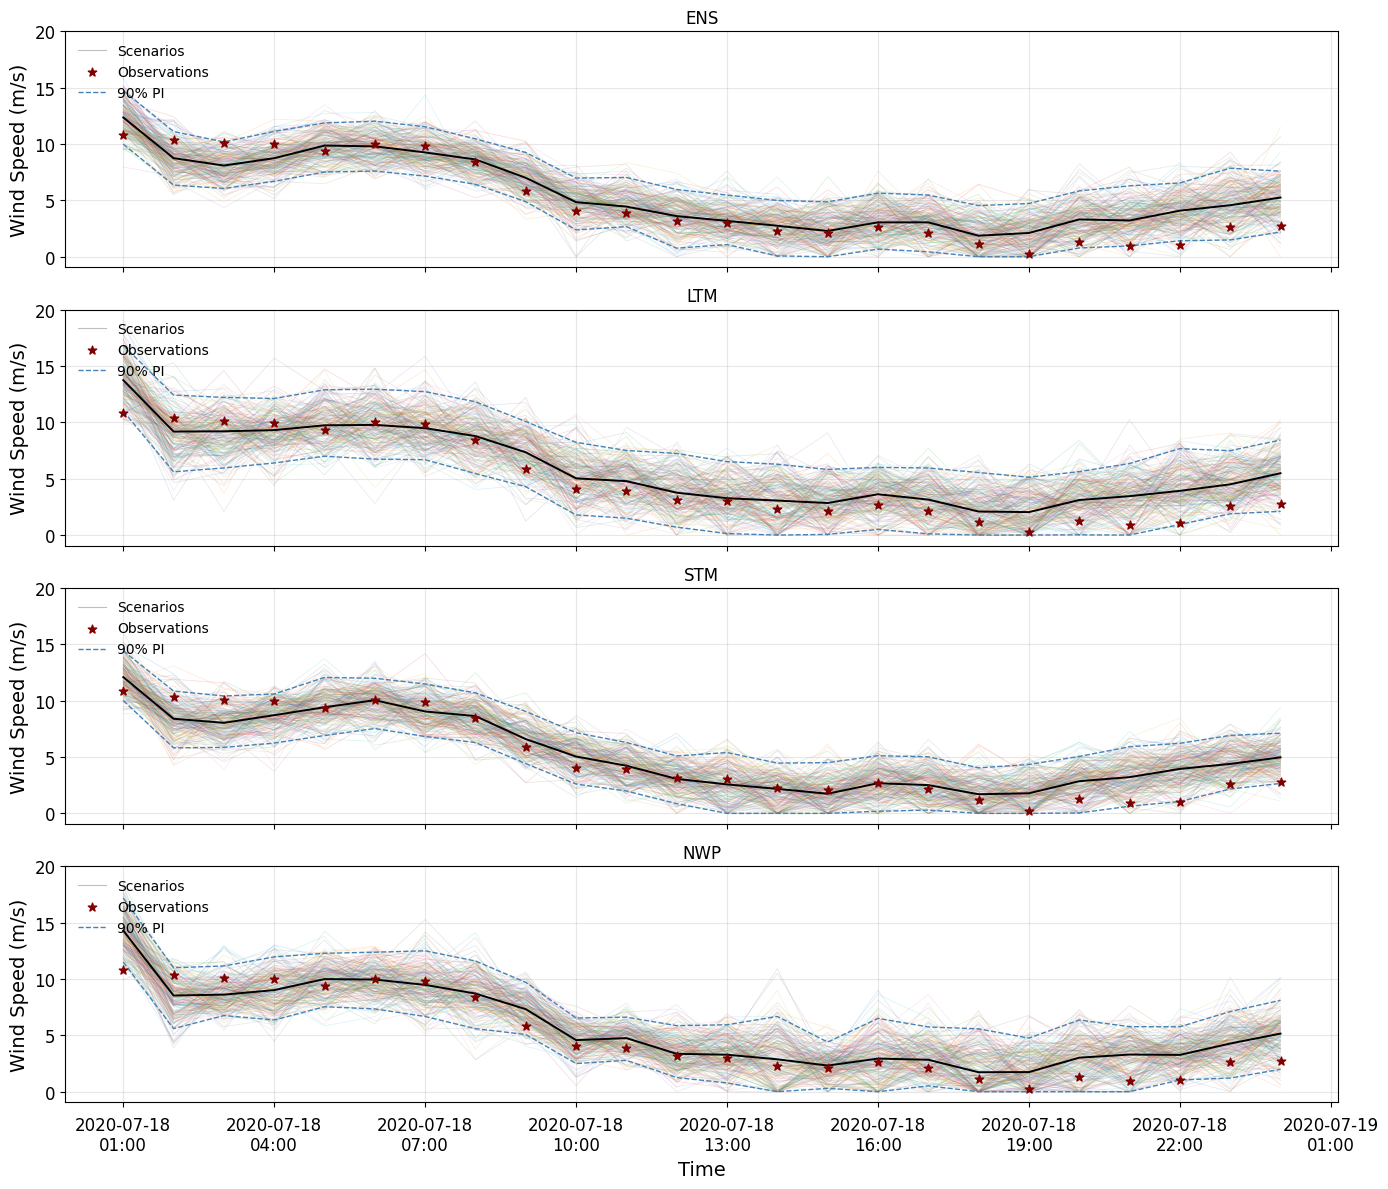

In [419]:
# 例如：画最近 10 天，段为 1-24，全局站点 7（=第8个站点，0基）
d = 125
plot_scenarios_three_models_range_stitched(
    muA_full, SigmaA_full,
    muB_full, SigmaB_full,
    muC_full, SigmaC_full,
    y_true,
    muN_full, SigmaN_full,[7,8],
    loc_global=7,
    loc_list_pair=[7,8],
    day_start=d, day_end=d,
    seg_name="1-24",
    full_start_datetime=datetime(2020,1,30,1,0,0),
    cut_first_days=45,
    L_total=9, order='loc_first',
    S_draw=200, seed=2024,
    clip_below_zero=True   # 场景负值截为0
)


In [ ]:
import numpy as np
import pandas as pd

# ========== 必备输入 ==========
# y_true: (24, 2, D)
# 对每个数据集：mu: (24, 2, D), sigma: (24, 2, D)
# 例：把你读入的数组放到下面列表：
# datasets = [("ModelA", muA, sigmaA), ("ModelB", muB, sigmaB), ...]
# y_true = ...  # 你的观测数组

# ========== 评估与采样设置（保持一致以便公平比较） ==========
S       = 1000      # 情景数
M_pairs = 10000     # 用于 E||X-X'|| 的随机配对数
seed    = 42        # 公用随机种子
use_temporal_corr = False  # True=考虑时间相关（RBF）
length_scale       = 2.0   # 仅在 use_temporal_corr=True 时生效

# ========== 基本检查 ==========
H, L, D = y_true.shape
assert (H, L) == (24, 2)
m = H * L
I24 = np.eye(24)

# ========== 公用随机数（CRN）：同一 eps/pairs 用于所有数据集 ==========
rng = np.random.default_rng(seed)
eps_bank = rng.standard_normal((D, S, m))  # 每日共用 S×48 的噪声，保证可比
i_pair = rng.integers(0, S, size=M_pairs)
j_pair = rng.integers(0, S, size=M_pairs)
mask   = (i_pair != j_pair)
i_pair, j_pair = i_pair[mask], j_pair[mask]

# ========== （可选）时间相关：构造 24×24 的 RBF 相关矩阵 ==========
if use_temporal_corr:
    t = np.arange(24, dtype=float)
    TT_i = t[:, None]; TT_j = t[None, :]
    dist2 = (TT_i - TT_j)**2
    R = np.exp(-0.5 * dist2 / (length_scale**2 + 1e-12))
    R = (R + R.T) / 2.0
    # 轻微抖动，避免临界不定
    jitter_R = 1e-10
    for _ in range(6):
        try:
            np.linalg.cholesky(R + jitter_R*np.eye(24))
            break
        except np.linalg.LinAlgError:
            jitter_R *= 10.0
    if jitter_R > 1e-10:
        R = R + jitter_R*np.eye(24)

# ========== 逐数据集计算 ES ==========
rows = []
for name, mu, sigma in datasets:
    # 基本形状一致性
    assert mu.shape   == (24, 2, D)
    assert sigma.shape== (24, 2, D)

    ES_daily = np.empty(D)

    for k in range(D):
        # —— 两站点各自 24×24 协方差的 Cholesky，并拼成 48 维块对角 ——
        Lblocks = []
        mu_flat = []
        y_flat  = []

        for loc in range(2):
            mu_loc = mu[:, loc, k]       # (24,)
            sd_loc = sigma[:, loc, k]    # (24,)
            var_loc= sd_loc**2

            if use_temporal_corr:
                # Sig = D^(1/2) R D^(1/2)；D^(1/2) = diag(sd)
                Sig = np.diag(sd_loc) @ R @ np.diag(sd_loc)
            else:
                Sig = np.diag(var_loc)   # 对角基线

            # 稳健 Cholesky
            jitter = 1e-6
            for _ in range(8):
                try:
                    Lc = np.linalg.cholesky(Sig + jitter*I24)
                    break
                except np.linalg.LinAlgError:
                    jitter *= 10.0

            Lblocks.append(Lc)
            mu_flat.append(mu_loc)
            y_flat.append(y_true[:, loc, k])

        # 48 维块对角下三角
        Lbd = np.zeros((m, m))
        Lbd[0:24,    0:24]     = Lblocks[0]
        Lbd[24:48,   24:48]    = Lblocks[1]
        mu_flat = np.concatenate(mu_flat, axis=0)  # (48,)
        y_flat  = np.concatenate(y_flat,  axis=0)  # (48,)

        # —— Monte Carlo 计算 Energy Score ——
        # X = mu + eps @ L^T
        eps = eps_bank[k]                    # (S, 48) —— CRN：同日同 eps
        X   = mu_flat[None, :] + eps @ Lbd.T # (S, 48)

        term1 = np.mean(np.linalg.norm(X - y_flat[None, :], axis=1))
        diffs = X[i_pair] - X[j_pair]
        term2 = 0.5 * np.mean(np.linalg.norm(diffs, axis=1))
        ES_daily[k] = float(term1 - term2)

    rows.append({
        "model": name,
        "ES_mean": float(ES_daily.mean()),
        "ES_std":  float(ES_daily.std(ddof=1)),
        "ES_p50":  float(np.median(ES_daily)),
        "ES_p90":  float(np.quantile(ES_daily, 0.90))
    })

df = pd.DataFrame(rows).sort_values("ES_mean")
print(df.to_string(index=False))


In [41]:
import numpy as np
from scipy.optimize import minimize, Bounds

# ====================== 固定输入参数与索引 ======================
loc_idx = [7, 8]        # 你要的两个地点（0基）
L_total = 9
ORDER   = 'loc_first'   # 216 的展平规则：'loc_first' 表示 (loc*24 + hour)
DAYS    = 183           # D

# ------------- 1) 构造 48维索引（一次性从216中取出两地点×24小时） -------------
if ORDER == 'loc_first':
    idx_loc0 = [loc_idx[0] * 24 + h for h in range(24)]
    idx_loc1 = [loc_idx[1] * 24 + h for h in range(24)]
elif ORDER == 'hour_first':
    idx_loc0 = [h * L_total + loc_idx[0] for h in range(24)]
    idx_loc1 = [h * L_total + loc_idx[1] for h in range(24)]
else:
    raise ValueError("ORDER must be 'loc_first' or 'hour_first'")
idx48 = np.array(idx_loc0 + idx_loc1, dtype=int)  # 48维在216中的位置

# ====================== 2) 均值与真值（拼成48维） ======================
# allY_Fore: (24, 9, 183) -> 先挑两个地点 -> (24,2,183) -> (D,2,24)
muY_2_24 = np.transpose(np.asarray(long_mat['allY_Fore'])[:, loc_idx, :], (2, 1, 0))
muX_2_24 = np.transpose(np.asarray(short_mat['allY_Fore'])[:, loc_idx, :], (2, 1, 0))
D = muY_2_24.shape[0]
assert (D,2,24) == muY_2_24.shape == muX_2_24.shape

# 48维（先地点7的24小时，再地点8的24小时）
muY48 = np.concatenate([muY_2_24[:,0,:], muY_2_24[:,1,:]], axis=1)  # (D,48)
muX48 = np.concatenate([muX_2_24[:,0,:], muX_2_24[:,1,:]], axis=1)  # (D,48)

# allY_Test: (24,2,183) -> (D,2,24)
y_raw = np.asarray(long_mat['allY_Test'])
assert y_raw.shape == (24,2,D), f"Expected (24,2,{D}), got {y_raw.shape}"
y_D_2_24 = np.transpose(y_raw, (2,1,0))                              # (D,2,24)
# -- 确保真值两个地点的顺序与 loc_idx 对齐；若不一致，这里调换 y_D_2_24[:,[1,0],:]
y_true48 = np.concatenate([y_D_2_24[:,0,:], y_D_2_24[:,1,:]], axis=1)  # (D,48)

# ====================== 3) 协方差（保留跨地点相关） ======================
# allVariance: (216,216,183) -> 每天切出 48×48 子矩阵
SigYY48 = np.empty((D, 48, 48))
SigXX48 = np.empty((D, 48, 48))
VarY_all = np.asarray(long_mat['allVariance'])   # (216,216,D)
VarX_all = np.asarray(short_mat['allVariance_Fore'])  # (216,216,D)
assert VarY_all.shape == (24*L_total, 24*L_total, D)
assert VarX_all.shape == (24*L_total, 24*L_total, D)

for d in range(D):
    SigYY48[d] = VarY_all[np.ix_(idx48, idx48, [d])].squeeze(-1)
    SigXX48[d] = VarX_all[np.ix_(idx48, idx48, [d])].squeeze(-1)

# ====================== 4) 以 ES 为目标做滚动标定 ======================
# 超参
Wwin    = 45          # 滚动窗口天数
S_train = 1000        # 训练时每日样本数（CRN）
S_eval  = 1000        # 评估样本数（独立）
seed    = 42
I48     = np.eye(48)
I24     = np.eye(24)

# 结果容器
eff         = D - Wwin
muZ_out     = np.empty((eff, 48))
SigZ_out    = np.empty((eff, 48, 48))
MAE_daily   = np.empty(eff)
ES_daily    = np.empty(eff)
alpha_seq   = np.empty(eff)
ell_seq     = np.empty(eff)
rho_seq     = np.empty(eff)

# 小工具：softplus/tanh 映射与 alpha 的硬约束
def inv_softplus(x): return np.log(np.exp(x) - 1.0)
a_low, a_high = inv_softplus(0.05), inv_softplus(0.15)
bounds = Bounds([a_low, -np.inf, -np.inf], [a_high, np.inf, np.inf])

# 小工具：构造小时核并谱归一化 -> 扩成 48 维的 Kronecker（I_2 ⊗ K_hour）
t = np.arange(24.0)
TT_i, TT_j = t[:,None], t[None,:]
def make_C48(ell, rho):
    K = np.exp(-0.5 * (TT_i - TT_j)**2 / (ell**2 + 1e-12))  # (24,24)
    # 谱归一化
    evals, _ = np.linalg.eigh((K + K.T)/2.0)
    Kt = K / max(evals.max(), 1e-12)
    # 扩到 48 维（两个地点共用同一个小时核，不引入额外的 XY 跨地点相关）
    C48 = rho * np.kron(np.eye(2), Kt)  # (48,48)
    return C48

# 公用随机数（CRN）生成器
rng_global = np.random.default_rng(seed)

# 初值（无约束参数 a,l,r）
theta_prev = np.array([0.1, 2.0, 0.0], dtype=float)

for d in range(Wwin, D):
    k   = d - Wwin
    win = np.arange(d - Wwin, d)

    # 预先生成窗口内 CRN 噪声：每个日 S_train 个 48 维标准正态
    eps_bank = rng_global.standard_normal((len(win), S_train, 48))

    # 预计算窗口内的边际 Cholesky（减少目标函数里的重复开销）
    Lx_list, Ly_list = [], []
    for s in win:
        # jitter 以保证数值正定
        jitter = 1e-6
        for _ in range(8):
            try:
                Lx = np.linalg.cholesky(SigXX48[s] + jitter * I48); break
            except np.linalg.LinAlgError:
                jitter *= 10.0
        jitter = 1e-6
        for _ in range(8):
            try:
                Ly = np.linalg.cholesky(SigYY48[s] + jitter * I48); break
            except np.linalg.LinAlgError:
                jitter *= 10.0
        Lx_list.append(Lx); Ly_list.append(Ly)

    # -------- 目标函数：窗口平均 Energy Score 的 MC 估计 --------
    def obj(theta):
        a, l, r = theta
        alpha = np.log1p(np.exp(a))         # α>0
        ell   = np.log1p(np.exp(l))         # ℓ>0
        rho   = np.tanh(r)                  # ρ∈(-1,1)
        # 逐小时权重 w_t=e^{-α(t+1)}；在 48 维上用 I_2 ⊗ diag(w)
        w = np.exp(-alpha * (np.arange(24) + 1.0))
        W48 = np.kron(np.eye(2), np.diag(w))
        ImW = np.eye(48) - W48
        # XY 跨模型相关核（48×48）
        C48 = make_C48(ell, rho)

        total = 0.0
        for jj, s in enumerate(win):
            # 融合均值
            muZ = W48 @ muX48[s] + ImW @ muY48[s]              # (48,)
            # 跨模型协方差（用边际 Cholesky 与 C48 构造）
            SigXY = Lx_list[jj] @ C48 @ Ly_list[jj].T          # (48,48)
            # 融合协方差
            SigZ  = (W48 @ SigXX48[s] @ W48
                     + ImW @ SigYY48[s] @ ImW
                     + W48 @ SigXY @ ImW
                     + ImW @ SigXY.T @ W48)                    # (48,48)

            # Cholesky（带 jitter）
            jitter = 1e-6
            for _ in range(8):
                try:
                    Lz = np.linalg.cholesky(SigZ + jitter * I48); break
                except np.linalg.LinAlgError:
                    jitter *= 10.0

            # 抽样并计算 ES = E||X-y|| - 0.5 E||X-X'||
            X = muZ[None,:] + eps_bank[jj] @ Lz.T              # (S_train,48)
            y = y_true48[s]                                     # (48,)
            term1 = np.mean(np.linalg.norm(X - y[None,:], axis=1))
            # 随机配对近似第二项（降低 O(S^2) 复杂度）
            S = S_train
            i_pair = rng_global.integers(0, S, size=10000)
            j_pair = rng_global.integers(0, S, size=10000)
            m = (i_pair != j_pair)
            diffs = X[i_pair[m]] - X[j_pair[m]]
            term2 = 0.5 * np.mean(np.linalg.norm(diffs, axis=1))

            total += (term1 - term2)

        return total / len(win)

    # L-BFGS-B + α 的硬约束 [0.05,0.15]
    opt = minimize(obj, theta_prev, method='L-BFGS-B',
                   bounds=bounds, options=dict(maxiter=200, ftol=1e-9))
    a_hat, l_hat, r_hat = opt.x
    alpha_hat = np.log1p(np.exp(a_hat))
    ell_hat   = np.log1p(np.exp(l_hat))
    rho_hat   = np.tanh(r_hat)
    alpha_seq[k], ell_seq[k], rho_seq[k] = alpha_hat, ell_hat, rho_hat
    theta_prev = opt.x

    # ---------- 用最优参数生成当天的融合分布，并打分 ----------
    w = np.exp(-alpha_hat * (np.arange(24) + 1.0))
    W48 = np.kron(np.eye(2), np.diag(w)); ImW = np.eye(48) - W48
    C48 = make_C48(ell_hat, rho_hat)

    # 当天边际 Cholesky
    jitter = 1e-6
    for _ in range(8):
        try:
            Lx = np.linalg.cholesky(SigXX48[d] + jitter * I48); break
        except np.linalg.LinAlgError: jitter *= 10.0
    jitter = 1e-6
    for _ in range(8):
        try:
            Ly = np.linalg.cholesky(SigYY48[d] + jitter * I48); break
        except np.linalg.LinAlgError: jitter *= 10.0

    muZ = W48 @ muX48[d] + ImW @ muY48[d]
    SigXY = Lx @ C48 @ Ly.T
    SigZ  = (W48 @ SigXX48[d] @ W48
             + ImW @ SigYY48[d] @ ImW
             + W48 @ SigXY @ ImW
             + ImW @ SigXY.T @ W48)

    # 保存
    muZ_out[k]  = muZ
    SigZ_out[k] = SigZ

    # 评估（独立随机数）
    rng_eval = np.random.default_rng(seed + 1000 + k)
    eps_eval = rng_eval.standard_normal((S_eval, 48))
    # Cholesky
    jitter = 1e-6
    for _ in range(8):
        try:
            Lz = np.linalg.cholesky(SigZ + jitter * I48); break
        except np.linalg.LinAlgError: jitter *= 10.0
    X_eval = muZ[None,:] + eps_eval @ Lz.T
    y = y_true48[d]
    term1 = np.mean(np.linalg.norm(X_eval - y[None,:], axis=1))
    i_eval = rng_eval.integers(0, S_eval, size=10000)
    j_eval = rng_eval.integers(0, S_eval, size=10000)
    m = (i_eval != j_eval)
    diffs = X_eval[i_eval[m]] - X_eval[j_eval[m]]
    term2 = 0.5 * np.mean(np.linalg.norm(diffs, axis=1))
    ES_daily[k] = float(term1 - term2)

    # MAE（48维）
    MAE_daily[k] = float(np.mean(np.abs(y - muZ)))

    if (k+1) % 10 == 0 or k == eff-1:
        print(f"[{k+1}/{eff}] alpha={alpha_hat:.4f}, ell={ell_hat:.3f}, rho={rho_hat:.3f}, "
              f"MAE={MAE_daily[k]:.4f}, ES={ES_daily[k]:.4f}")

print("Overall MAE:", float(np.mean(MAE_daily)), "Overall ES:", float(np.mean(ES_daily)))


[10/138] alpha=0.1500, ell=2.127, rho=0.000, MAE=1.5150, ES=8.9802
[20/138] alpha=0.1500, ell=2.127, rho=0.000, MAE=1.1364, ES=7.7887


/var/folders/z4/sfjcxx3s1px_qp22m2z82c9m0000gn/T/ipykernel_85210/3418048452.py:123: RuntimeWarning: overflow encountered in exp
  ell   = np.log1p(np.exp(l))         # ℓ>0


KeyboardInterrupt: 

In [51]:
muZ_out[0,:]

array([ 6.66886942,  7.72839283,  9.37060693, 14.35990787, 19.1646756 ,
       10.44389278,  9.88681124,  8.98531072,  8.88534309,  8.93197055,
        8.38720733,  8.43484315,  8.8816916 ,  8.47396859,  8.28419745,
        8.43309545,  8.50125499,  7.99031922,  7.57772275,  6.69815573,
        6.08732392,  5.0875178 ,  4.39436816,  4.18839281,  4.1576722 ,
        3.64375505,  2.94091265,  7.67458022, 13.28083733, 12.1666901 ,
       10.5518801 ,  7.50211564,  8.61351141,  7.92659181,  8.3913186 ,
        8.20153837,  8.48407273,  8.75328281,  8.56580198,  8.43520265,
        8.39822488,  8.40188534,  7.93185177,  7.17201247,  6.59358665,
        5.76844827,  4.81114848,  4.52704569])

In [54]:
y_true48[45,:]

array([ 6.37816667,  8.31771667, 11.16971667, 12.38286667, 13.29496667,
       10.22513333,  8.11386667,  7.95648333,  8.46043333,  5.56738333,
        6.39501667,  6.23216667,  7.42435   ,  8.1237    ,  8.81118333,
        8.30111667,  8.2058    ,  6.77046667,  5.56908333,  4.03005   ,
        2.56351667,  1.41851667,  1.3824    ,  1.90585   ,  3.2496    ,
        4.76255   ,  9.10696667, 14.97048333, 14.58758333, 13.24945   ,
       11.09306667,  5.19191667,  6.31591667,  5.47158333,  6.05983333,
        5.79715   ,  4.95135   ,  6.55586667,  8.23748333,  7.81406667,
        8.26816667,  7.5028    ,  5.79106667,  5.56898333,  4.45058333,
        3.83773333,  5.12676667,  5.6734    ])